In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy, generate_momentum_signal

In [ ]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

In [ ]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)

#### 89 Trade Count Strategy

In [5]:
def generate_random_signal_v3(prices, lookback):

    possible_trade_days = np.arange(lookback + 1, len(prices) - 1)

    trade_days = np.random.choice(possible_trade_days, size = 89, replace = False)
    trade_days = np.sort(trade_days)

    random_signal = [np.nan] * lookback

    state = 0

    for i in range(lookback, len(prices)):
        if i in trade_days:
            state = 1 - state

        random_signal.append(state) 

    return random_signal

In [6]:
random_signal = generate_random_signal_v3(prices, lookback)

random_df, random_result = backtester(returns, random_signal, 0.001)
pd.Series(random_result)

total_return          1.491151
cagr                  0.036247
annual_volatility     0.135029
annual_sharpe         0.331220
max_drawdown         -0.516354
calmar                0.070198
time_invested         0.517647
trades               89.000000
dtype: float64

In [7]:
def run_simulation_v3(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v3(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [8]:
np.random.seed(44)

simulation_output = run_simulation_v3(1000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,2.094666,0.045053,0.108100,0.462097,-0.291098,0.154771,0.416254,89
1,6.207126,0.080092,0.114809,0.728532,-0.221963,0.360834,0.510217,89
2,1.315091,0.033288,0.132055,0.313943,-0.438860,0.075852,0.418731,89
3,1.096232,0.029293,0.117943,0.303794,-0.306537,0.095562,0.481424,89
4,1.217444,0.031553,0.134885,0.297689,-0.479669,0.065780,0.487461,89
...,...,...,...,...,...,...,...,...
995,1.111476,0.029584,0.138982,0.279237,-0.483231,0.061222,0.443034,89
996,2.704254,0.052409,0.135971,0.443532,-0.490636,0.106819,0.543808,89
997,1.724734,0.039876,0.121139,0.383298,-0.404592,0.098559,0.482353,89
998,1.978287,0.043492,0.142057,0.370707,-0.445797,0.097560,0.454799,89


In [9]:
print(f"Sharpe Average: {simulation_df['annual_sharpe'].mean():.4f}")
print(f"Sharpe Median:  {simulation_df['annual_sharpe'].median():.4f}")
print(f"Largest Sharpe: {simulation_df['annual_sharpe'].max():.4f}")
print(f"Average No. of Trades: {simulation_df['trades'].mean():.4f}")
print(f"Average Time Invested: {simulation_df['time_invested'].mean():.4f}")

Sharpe Average: 0.3739
Sharpe Median:  0.3695
Largest Sharpe: 0.7527
Average No. of Trades: 89.0000
Average Time Invested: 0.4999


In [19]:
fraction_numerator = 0

simulation_sharpe_ratio = simulation_df["annual_sharpe"]

for i in range(len(simulation_sharpe_ratio)):
    if simulation_sharpe_ratio[i] >= momentum_results["annual_sharpe"]:
        fraction_numerator += 1

p_value = fraction_numerator/len(simulation_sharpe_ratio)

print("Empirical p-value:", p_value)

Empirical p-value: 0.029


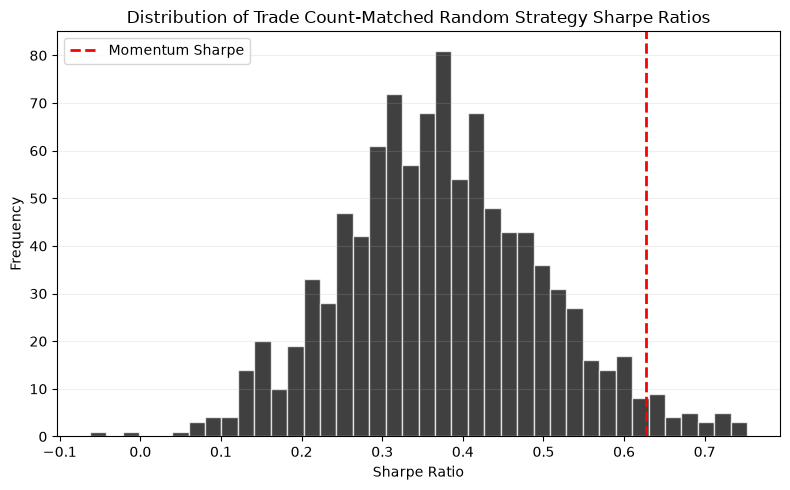

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(
    simulation_df["annual_sharpe"],
    bins=40,
    color="black",
    alpha=0.75,
    edgecolor="white"
)

plt.axvline(
    momentum_results["annual_sharpe"],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Momentum Sharpe"
)

plt.xlabel("Sharpe Ratio")
plt.ylabel("Frequency")
plt.title("Distribution of Trade Count-Matched Random Strategy Sharpe Ratios")

plt.legend()

plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()